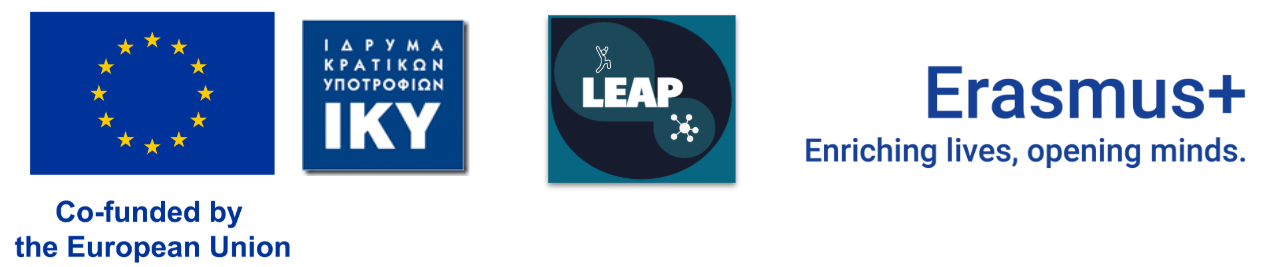

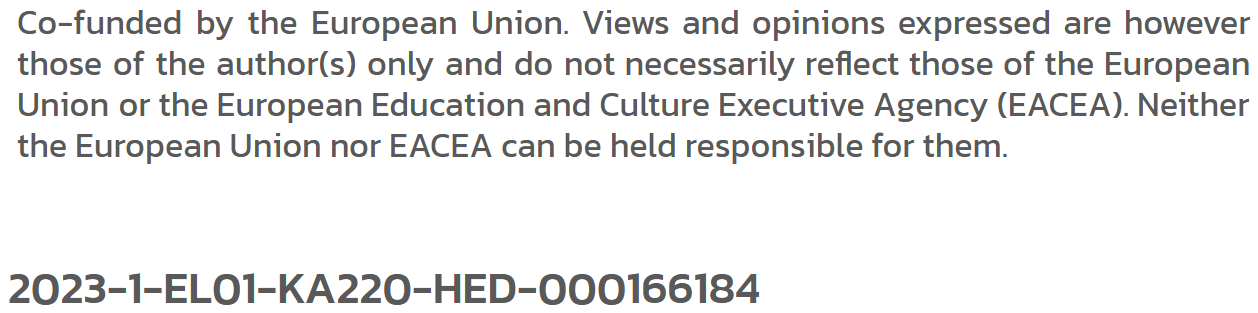

# Final Project, Option 1: Where does your CNN make its mistakes?

Software that reads handwritten numbers, such as postcodes on envelopes or account numbers on paper forms, must be judged not only on how often it is right but on where it goes wrong, because a confident misreading carries a real cost. In this project you build such a model and study the mistakes it makes.

In this project you build a convolutional neural network that recognises handwritten digits, then you study the mistakes it makes.

**Central question:** where does your CNN make its mistakes, and does one change to the model move them?

The data set is MNIST: 70,000 images of handwritten digits, each 28 by 28 pixels in greyscale, labelled 0 to 9. You download it yourself in the next cell.

This project draws on two earlier modules. In Module 5, we built and trained dense neural networks in Keras. In Module 6, we added convolutional layers, used Dropout and EarlyStopping to control overfitting, and read a confusion matrix to see which classes a model mixes up. Here you bring those skills together on a larger, more varied data set.

**How this notebook is organised.** The cells in Part A are already written for you. They handle the import, the download, and the reshaping that turns each flat row of 784 numbers back into a 28 by 28 image. From Part B onward, the cells are yours to complete. Each one carries comments describing what to do, along with a few hints, but not the finished code. Work through them in order.

Training on the full data set may take a few minutes per epoch on a laptop without a graphics card. This is expected.

## Part A. Setup and data

We start with the imports. This cell loads everything the notebook needs, so we run it once at the top.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import keras
from keras import layers

### Loading the data

We download MNIST from OpenML. The call returns the images in `X` as 70,000 rows of 784 numbers, and the labels in `y` as text. We convert the labels to integers so the model can work with them. The download runs once and may take a moment.

In [2]:
X, y = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    return_X_y=True
)

y = y.astype(int)

print("Images:", X.shape)
print("Labels:", y.shape, "| classes:", np.unique(y))

Images: (70000, 784)
Labels: (70000,) | classes: [0 1 2 3 4 5 6 7 8 9]


### Preparing the images

Each row of `X` is one image flattened into a line of 784 numbers. We reshape every row back into a 28 by 28 image with a single greyscale channel, and we scale the pixel values from the range 0 to 255 down to the range 0 to 1, which helps the network train. We then split the data into a training set and a test set, keeping the class balance with `stratify`, as we did in Module 3.

In [3]:
X = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training images:", X_train.shape)
print("Test images:    ", X_test.shape)

# If training is slow on your machine, you may work with a smaller sample
# while you get everything running, for example:
#   X_train, y_train = X_train[:10000], y_train[:10000]

Training images: (56000, 28, 28, 1)
Test images:     (14000, 28, 28, 1)


### A first look at the images

Before modelling, we look at a few training images with their labels, to confirm the data loaded correctly.

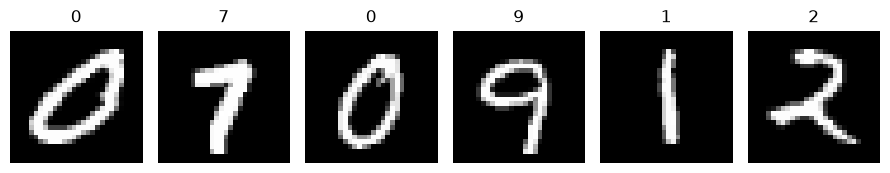

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, image, label in zip(axes, X_train, y_train):
    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(str(label))
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part B. Build and train your network

From here on, the cells are yours to complete.

First, build a convolutional neural network with the Keras Sequential API, the same style you used in Module 6. Recall the shape of one image: 28 by 28, with one channel.

In [5]:
# Build a small convolutional network with the Keras Sequential API.
# Fix the random seed so that rerunning the notebook gives comparable results.
keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

Compiling sets the optimiser, the loss function, and the metric to watch during training.

In [6]:
# Compile the model: Adam optimiser, sparse categorical crossentropy (integer labels), accuracy metric.
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])


### Train the model

Train the network, watching how it performs on data it has not learnt from. `EarlyStopping` halts training once the validation loss stops improving, so you do not waste time or overfit.

In [7]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                           restore_best_weights=True)

history = model.fit(X_train, y_train,
                    validation_split=0.1,
                    epochs=15,
                    batch_size=128,
                    callbacks=[early_stop],
                    verbose=2)


Epoch 1/15
394/394 - 14s - 35ms/step - accuracy: 0.9092 - loss: 0.3206 - val_accuracy: 0.9636 - val_loss: 0.1290
Epoch 2/15
394/394 - 15s - 39ms/step - accuracy: 0.9684 - loss: 0.1088 - val_accuracy: 0.9730 - val_loss: 0.0857
Epoch 3/15
394/394 - 15s - 37ms/step - accuracy: 0.9768 - loss: 0.0782 - val_accuracy: 0.9784 - val_loss: 0.0675
Epoch 4/15
394/394 - 16s - 39ms/step - accuracy: 0.9813 - loss: 0.0615 - val_accuracy: 0.9804 - val_loss: 0.0619
Epoch 5/15
394/394 - 17s - 44ms/step - accuracy: 0.9834 - loss: 0.0530 - val_accuracy: 0.9827 - val_loss: 0.0552
Epoch 6/15
394/394 - 16s - 40ms/step - accuracy: 0.9855 - loss: 0.0444 - val_accuracy: 0.9832 - val_loss: 0.0526
Epoch 7/15
394/394 - 15s - 38ms/step - accuracy: 0.9879 - loss: 0.0380 - val_accuracy: 0.9861 - val_loss: 0.0494
Epoch 8/15
394/394 - 14s - 34ms/step - accuracy: 0.9885 - loss: 0.0348 - val_accuracy: 0.9877 - val_loss: 0.0448
Epoch 9/15
394/394 - 14s - 34ms/step - accuracy: 0.9904 - loss: 0.0305 - val_accuracy: 0.9877 - 

### Learning curves

Plot the training and validation loss across the epochs. A validation curve that flattens or turns upward while the training curve keeps falling is a sign of overfitting.

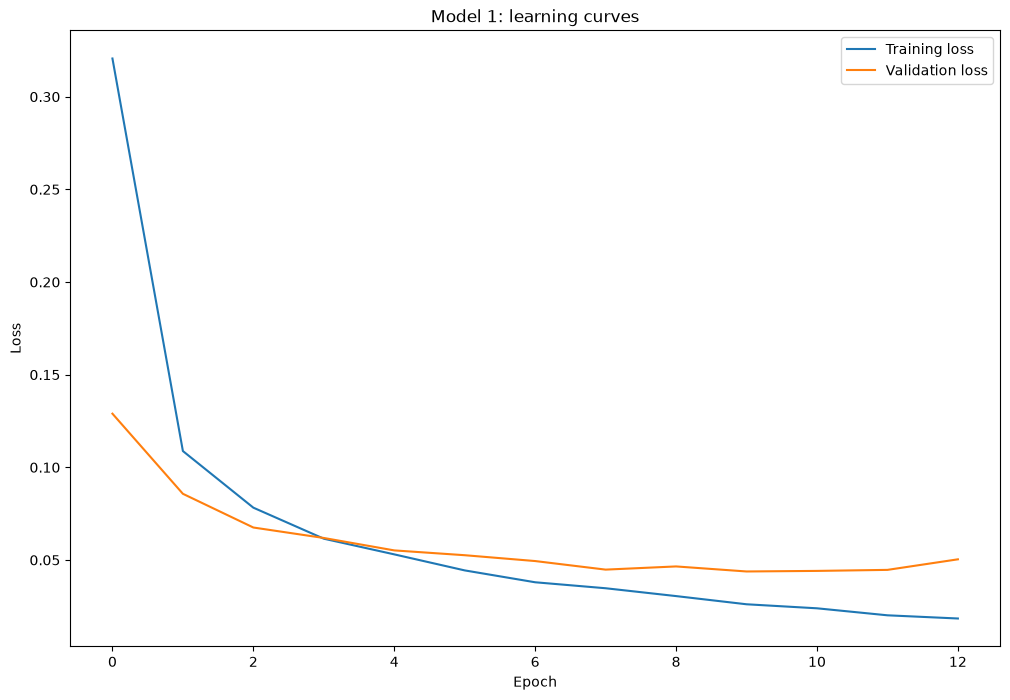

In [8]:
plt.figure(figsize=(12, 8))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 1: learning curves")
plt.legend()
plt.show()


## Part C. Read the mistakes

Now measure how well the model does on the test set, the images it has never seen. This gives a reliable estimate of how it will perform on new images.

In [9]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Model 1 test loss:     {test_loss:.4f}")
print(f"Model 1 test accuracy: {test_accuracy:.4f}")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
print("Misclassified test images:", int((y_pred != y_test).sum()), "of", len(y_test))


Model 1 test loss:     0.0463
Model 1 test accuracy: 0.9869
Misclassified test images: 183 of 14000


### The confusion matrix

The confusion matrix is where you answer the first half of the central question: where the mistakes are. Read it by rows. Each row is a true digit, each column is the digit the model predicted. The diagonal holds the correct predictions; every off-diagonal cell is a mistake, and its position tells you which digit was mistaken for which.

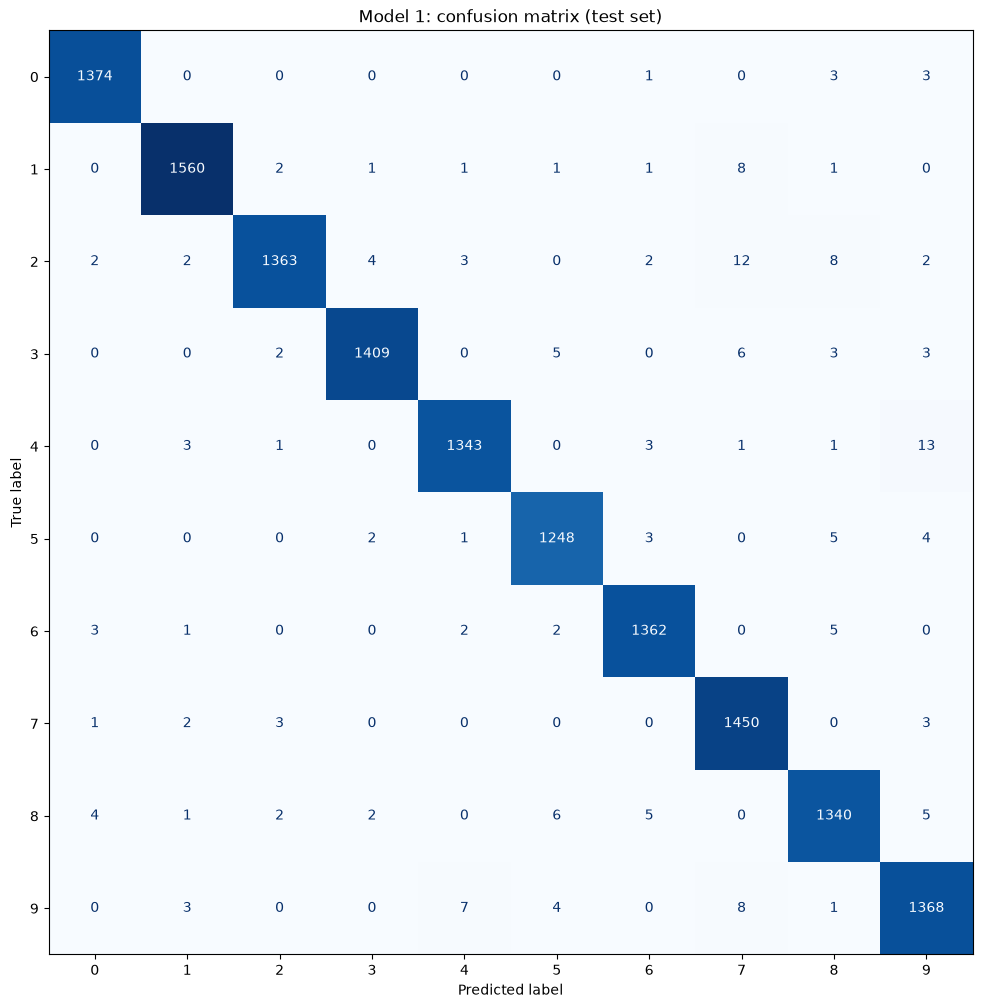

Most frequent confusions (true -> predicted : count)
  4 -> 9 : 13
  2 -> 7 : 12
  9 -> 7 : 8
  2 -> 8 : 8
  1 -> 7 : 8
  9 -> 4 : 7


In [10]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Model 1: confusion matrix (test set)")
plt.show()

# The largest off-diagonal cells, i.e. the most frequent mistakes
off = cm.copy()
np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1], off.shape))[0][:6]
print("Most frequent confusions (true -> predicted : count)")
for t, p in top:
    print(f"  {t} -> {p} : {off[t, p]}")


### What did you find?

Look at the off-diagonal cells with the largest counts. Which pairs of digits does your model confuse most often? Some pairs are visually similar and are commonly mixed up.

**Write two or three sentences here** naming the two most common confusion pairs, recording the count for each one, and suggesting why those particular digits might be hard to tell apart. For example, if row 4 and column 9 contains 18, the model predicted 9 for 18 images that were actually 4.

**My answer**. The two most common confusions were true 4 predicted as 9 (13 images) and true 2 predicted as 7 (12 images). A handwritten 4 can resemble a 9 when its top is closed, while a 2 with a straight diagonal and little curl at the bottom can resemble a 7. These similar shapes likely explain why those pairs were confused most often.

## Part D. One change

Now answer the second half of the central question: does one change to the model move the mistakes?

Choose **one** change from the two below. Do not make both at once, or you will not know which one caused any difference you see.

- **Option A: a deeper network.** Before the Flatten layer, add `Conv2D(64, (3, 3), activation="relu")` followed by `MaxPooling2D((2, 2))`. This lets the network learn more detailed patterns.
- **Option B: stronger regularisation.** Raise the Dropout rate from 0.3 to 0.5. This makes the network rely less on any single feature.

**Before you run anything, write down your prediction:** will your chosen change raise the test accuracy, and will it reduce the confusion between the pairs you found in Part C? Note it here.

Neural-network training contains some randomness. A very small difference in accuracy does not necessarily show that one model is genuinely better. Look at the size of the difference and at the specific mistakes, not only at which accuracy is larger.

**My prediction** (written before running Model 2). I chose Option A, the deeper network. I expect the test accuracy to improve slightly and the confusion between 4 and 9 and between 2 and 7 to decrease, because the additional convolutional block may learn more detailed shape features.

In [11]:
# Model 2: identical to Model 1 except for ONE change (Option A): a second
# Conv2D(64) + MaxPooling2D block is added before the Flatten layer.
keras.utils.set_random_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),   # <- the one change
    layers.MaxPooling2D((2, 2)),                    # <- the one change
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model2.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

early_stop2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                            restore_best_weights=True)

history2 = model2.fit(X_train, y_train,
                      validation_split=0.1,
                      epochs=15,
                      batch_size=128,
                      callbacks=[early_stop2],
                      verbose=2)


Epoch 1/15
394/394 - 22s - 57ms/step - accuracy: 0.9164 - loss: 0.2834 - val_accuracy: 0.9779 - val_loss: 0.0783
Epoch 2/15
394/394 - 18s - 45ms/step - accuracy: 0.9756 - loss: 0.0786 - val_accuracy: 0.9804 - val_loss: 0.0602
Epoch 3/15
394/394 - 19s - 49ms/step - accuracy: 0.9825 - loss: 0.0555 - val_accuracy: 0.9843 - val_loss: 0.0490
Epoch 4/15
394/394 - 14s - 35ms/step - accuracy: 0.9863 - loss: 0.0448 - val_accuracy: 0.9870 - val_loss: 0.0410
Epoch 5/15
394/394 - 18s - 44ms/step - accuracy: 0.9882 - loss: 0.0373 - val_accuracy: 0.9877 - val_loss: 0.0402
Epoch 6/15
394/394 - 15s - 39ms/step - accuracy: 0.9896 - loss: 0.0328 - val_accuracy: 0.9873 - val_loss: 0.0373
Epoch 7/15
394/394 - 18s - 46ms/step - accuracy: 0.9909 - loss: 0.0287 - val_accuracy: 0.9889 - val_loss: 0.0377
Epoch 8/15
394/394 - 17s - 44ms/step - accuracy: 0.9916 - loss: 0.0254 - val_accuracy: 0.9886 - val_loss: 0.0389
Epoch 9/15
394/394 - 17s - 43ms/step - accuracy: 0.9932 - loss: 0.0220 - val_accuracy: 0.9887 - 

Model 1 test accuracy: 0.9869  (loss 0.0463)
Model 2 test accuracy: 0.9893  (loss 0.0351)
Errors: model 1 = 183 | model 2 = 150


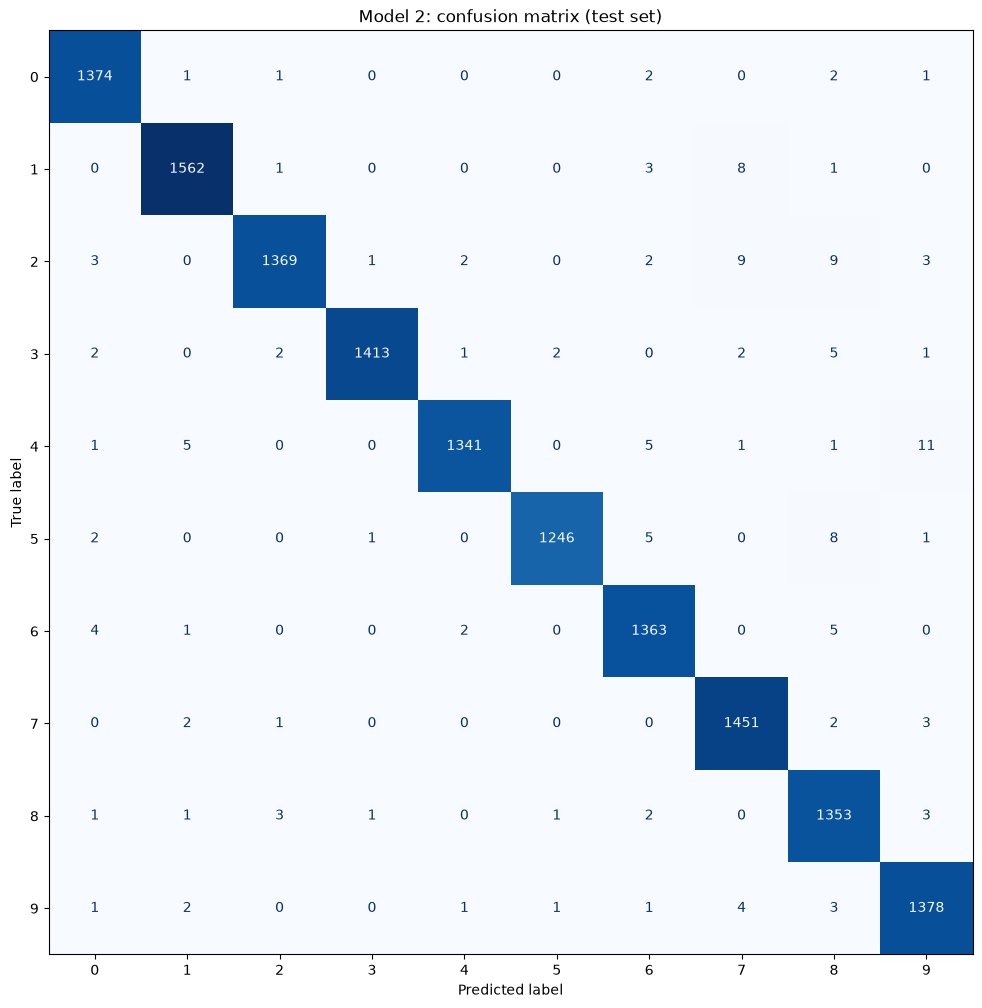


Pair (true -> predicted) | model 1 | model 2
  4 -> 9                  |      13 |      11
  2 -> 7                  |      12 |       9

Errors per true digit (model 1 / model 2):
  digit 0:   7 /   7
  digit 1:  15 /  13
  digit 2:  35 /  29
  digit 3:  19 /  15
  digit 4:  22 /  24
  digit 5:  15 /  17
  digit 6:  13 /  12
  digit 7:   9 /   8
  digit 8:  25 /  12
  digit 9:  23 /  13


In [13]:
test_loss2, test_accuracy2 = model2.evaluate(X_test, y_test, verbose=0)
print(f"Model 1 test accuracy: {test_accuracy:.4f}  (loss {test_loss:.4f})")
print(f"Model 2 test accuracy: {test_accuracy2:.4f}  (loss {test_loss2:.4f})")
print("Errors: model 1 =", int((y_pred != y_test).sum()), "| model 2 =", int((model2.predict(X_test, verbose=0).argmax(axis=1) != y_test).sum()))

y_pred2 = model2.predict(X_test, verbose=0).argmax(axis=1)
cm2 = confusion_matrix(y_test, y_pred2)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm2, display_labels=np.arange(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Model 2: confusion matrix (test set)")
plt.show()

# Compare the two most frequent confusion pairs from Part C, before and after
off1 = cm.copy(); np.fill_diagonal(off1, 0)
pairs = [tuple(p) for p in np.dstack(np.unravel_index(np.argsort(off1.ravel())[::-1], off1.shape))[0][:2]]
print("\nPair (true -> predicted) | model 1 | model 2")
for t, p in pairs:
    print(f"  {t} -> {p}                  | {cm[t, p]:7d} | {cm2[t, p]:7d}")

# Which classes changed the most overall?
off2 = cm2.copy(); np.fill_diagonal(off2, 0)
print("\nErrors per true digit (model 1 / model 2):")
for d in range(10):
    print(f"  digit {d}: {off1[d].sum():3d} / {off2[d].sum():3d}")


### Ethical considerations

A digit reader does not perform equally well for everyone. Handwriting varies by age, country, and schooling, and a model trained mostly on one style may read another less reliably.
**Write two or three sentences here** on the risks of putting this model into a real reading pipeline. Consider whose handwriting might be under-represented in the training data, and what the consequence of a confident but wrong reading would be in the setting above.

**My answer**. MNIST was written by American Census Bureau employees and high-school students, so handwriting styles from other countries, age groups, or schools may be under-represented and could be misread more often. In a real system, a confident wrong reading could send a letter or payment to the wrong place, so uncertain or high-value cases should be reviewed by a person and the model should be tested on the population it will actually serve.


## Wrapping up

Bring your findings together. **Write a short paragraph** that answers the central question directly:

- Where did your first model make most of its mistakes?
- Did your prediction in Part D turn out to be correct?
- For each of the two confusion pairs you identified, what was the count before and after the change?
- Did your one change move the mistakes, and is the difference large enough to be meaningful?

**What to hand in:** this completed notebook, with both confusion matrices visible in the output, and your written answers in the three markdown cells above (Part C, Part D, and this one).

**My answer**. The first model made 183 errors on the 14,000 test images (98.69% accuracy), and its mistakes clustered on digits with overlapping shapes: the most frequent were 4 read as 9 (13 images) and 2 read as 7 (12 images), and by true digit the 2 (35 errors), 8 (25) and 9 (23) were the hardest. My Part D prediction was partly right: I chose the deeper network (Option A) and expected a slight increase in accuracy and fewer 4-to-9 and 2-to-7 errors. Accuracy rose from 98.69% to 98.93% (150 errors instead of 183), while 4 to 9 fell from 13 to 11 and 2 to 7 from 12 to 9. The change moved the mistakes more clearly elsewhere, since errors on the digits 8 and 9 roughly halved (25 to 12 and 23 to 13), while 4 and 5 got slightly worse (22 to 24 and 15 to 17). Because I trained each model once with one seed on a single split, and the overall gain is only about a quarter of a percentage point, I would call this a small observed improvement, but not enough evidence to conclude that the deeper network is consistently better. Repeating the training with several seeds would be the next step.